**3 Departments**

--- QAP Optimization Results ---
Optimal Assignment: {'ICU': 'B', 'Radiology': 'A', 'Emergency': 'C'}
Minimum Total Cost: 1700
------------------------------


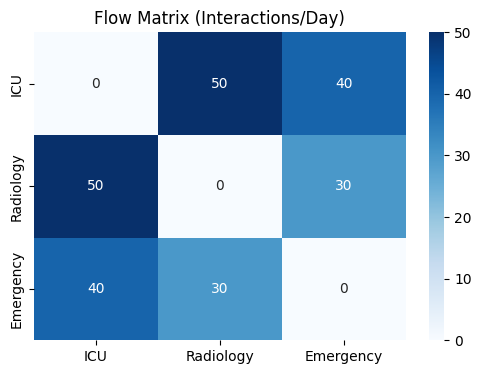

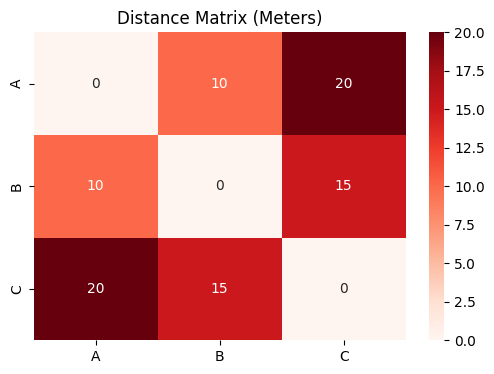

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Departments: 0=ICU, 1=Radiology, 2=Emergency
flow_matrix = np.array([
    [0, 50, 40],
    [50, 0, 30],
    [40, 30, 0]
])
# Locations: 0=A, 1=B, 2=C
distance_matrix = np.array([
    [0, 10, 20],
    [10, 0, 15],
    [20, 15, 0]
])

departments = ["ICU", "Radiology", "Emergency"]
locations = ["A", "B", "C"]
n = len(flow_matrix)

# --- Cost Calculation Function ---

def calculate_cost(flow, distance, assignment):

    total_cost = 0
    for i in range(n):
        for j in range(i+1, n):
            total_cost += flow[i][j] * distance[assignment[i]][assignment[j]]
    return total_cost

# --- Optimization Logic ---
# Generate all possible assignments

location_indices = list(range(n))
assignments = itertools.permutations(location_indices)

# Find the optimal assignment
min_cost = float('inf')
optimal_assignment_indices = None

for assignment_indices in assignments:
    cost = calculate_cost(flow_matrix, distance_matrix, assignment_indices)

    if cost < min_cost:
        min_cost = cost
        optimal_assignment_indices = assignment_indices

# Map indices to department and location names for clear output
optimal_assignment_names = {
    departments[i]: locations[optimal_assignment_indices[i]] for i in range(n)
}

print("--- QAP Optimization Results ---")
print(f"Optimal Assignment: {optimal_assignment_names}")
print(f"Minimum Total Cost: {min_cost}")
print("-" * 30)

# --- Data Visualization ---

# Heatmap for Flow Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(flow_matrix, annot=True, cmap="Blues",
            xticklabels=departments, yticklabels=departments)
plt.title("Flow Matrix (Interactions/Day)")
plt.show()

# Heatmap for Distance Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(distance_matrix, annot=True, cmap="Reds",
            xticklabels=locations, yticklabels=locations)
plt.title("Distance Matrix (Meters)")
plt.show()

**4th Department Added**

--- QAP Optimization Results ---
Optimal Assignment: {'ICU': 'B', 'Radiology': 'C', 'Emergency': 'D', 'Surgery': 'A'}
Minimum Total Cost: 4115
------------------------------


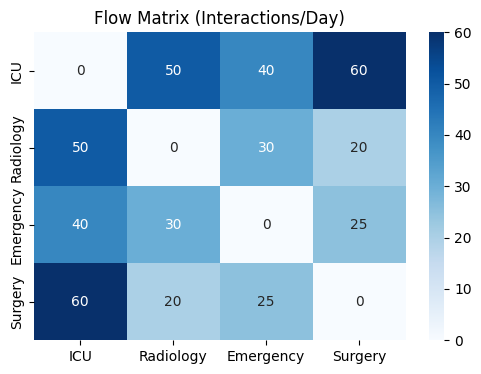

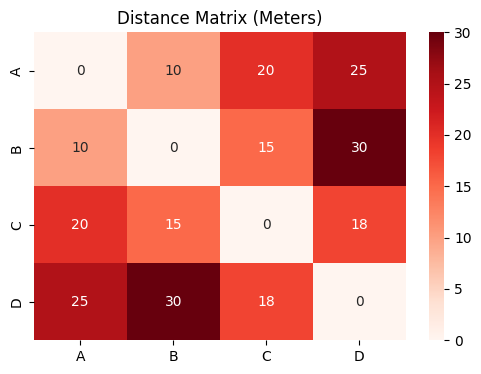

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Departments: 0=ICU, 1=Radiology, 2=Emergency, 3=Surgery
flow_matrix = np.array([
    [0, 50, 40, 60],
    [50, 0, 30, 20],
    [40, 30, 0, 25],
    [60, 20, 25, 0]
])

# Locations: 0=A, 1=B, 2=C, 3=D
distance_matrix = np.array([
    [0, 10, 20, 25],
    [10, 0, 15, 30],
    [20, 15, 0, 18],
    [25, 30, 18, 0]
])

departments = ["ICU", "Radiology", "Emergency", "Surgery"]
locations = ["A", "B", "C", "D"]
n = len(flow_matrix)

# --- Cost Calculation Function ---
def calculate_cost(flow, distance, assignment):
    total_cost = 0
    for i in range(n):
        for j in range(i+1, n):
            total_cost += flow[i][j] * distance[assignment[i]][assignment[j]]
    return total_cost

# --- Optimization Logic ---
location_indices = list(range(n))
assignments = itertools.permutations(location_indices)

min_cost = float('inf')
optimal_assignment_indices = None

for assignment_indices in assignments:
    cost = calculate_cost(flow_matrix, distance_matrix, assignment_indices)
    if cost < min_cost:
        min_cost = cost
        optimal_assignment_indices = assignment_indices

optimal_assignment_names = {
    departments[i]: locations[optimal_assignment_indices[i]] for i in range(n)
}

print("--- QAP Optimization Results ---")
print(f"Optimal Assignment: {optimal_assignment_names}")
print(f"Minimum Total Cost: {min_cost}")
print("-" * 30)

# --- Visualization ---

plt.figure(figsize=(6, 4))
sns.heatmap(flow_matrix, annot=True, cmap="Blues",
            xticklabels=departments, yticklabels=departments)
plt.title("Flow Matrix (Interactions/Day)")
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(distance_matrix, annot=True, cmap="Reds",
            xticklabels=locations, yticklabels=locations)
plt.title("Distance Matrix (Meters)")
plt.show()


**One Fixed**

--- QAP Optimization Results ---
✅ Optimal (Free) Assignment: {'ICU': 'B', 'Radiology': 'C', 'Emergency': 'D', 'Surgery': 'A'}
   → Minimum Total Cost: 4115

📍Optimal (Fixed Radiology at C) Assignment: {'ICU': 'B', 'Radiology': 'C', 'Emergency': 'D', 'Surgery': 'A'}
   → Minimum Total Cost: 4115

💡 Cost Difference: 0
----------------------------------------


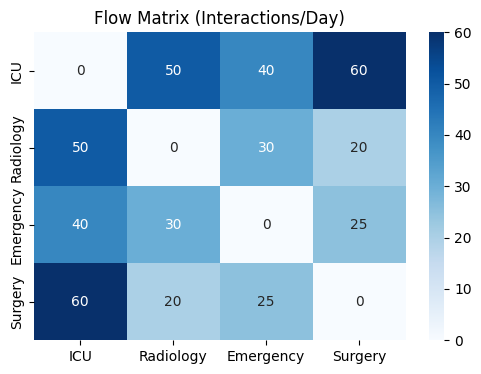

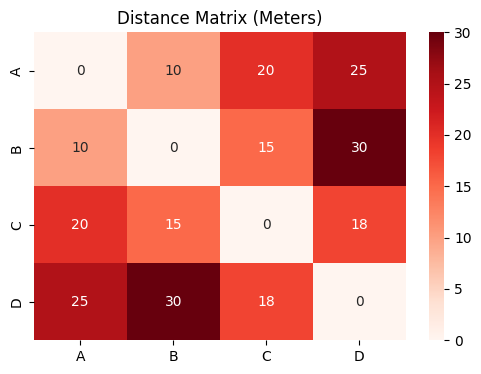

In [ ]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Departments: 0=ICU, 1=Radiology, 2=Emergency, 3=Surgery
flow_matrix = np.array([
    [0, 50, 40, 60],
    [50, 0, 30, 20],
    [40, 30, 0, 25],
    [60, 20, 25, 0]
])

# Locations: 0=A, 1=B, 2=C, 3=D
distance_matrix = np.array([
    [0, 10, 20, 25],
    [10, 0, 15, 30],
    [20, 15, 0, 18],
    [25, 30, 18, 0]
])

departments = ["ICU", "Radiology", "Emergency", "Surgery"]
locations = ["A", "B", "C", "D"]
n = len(flow_matrix)

# --- Cost Calculation Function ---
def calculate_cost(flow, distance, assignment):
    total_cost = 0
    for i in range(n):
        for j in range(i + 1, n):
            total_cost += flow[i][j] * distance[assignment[i]][assignment[j]]
    return total_cost

# --- Find optimal assignment with NO fixed constraint ---
location_indices = list(range(n))
assignments = itertools.permutations(location_indices)

min_cost_free = float('inf')
optimal_assignment_free = None

for assignment in assignments:
    cost = calculate_cost(flow_matrix, distance_matrix, assignment)
    if cost < min_cost_free:
        min_cost_free = cost
        optimal_assignment_free = assignment

optimal_assignment_free_names = {
    departments[i]: locations[optimal_assignment_free[i]] for i in range(n)
}

# --- Find optimal assignment WITH one department fixed ---
fixed_department = "Radiology"
fixed_location = "C"

fixed_dep_index = departments.index(fixed_department)
fixed_loc_index = locations.index(fixed_location)

remaining_deps = [i for i in range(n) if i != fixed_dep_index]
remaining_locs = [i for i in range(n) if i != fixed_loc_index]

min_cost_fixed = float('inf')
optimal_assignment_fixed = None

for perm in itertools.permutations(remaining_locs):
    current_assignment = [None] * n
    current_assignment[fixed_dep_index] = fixed_loc_index
    for i, dep in enumerate(remaining_deps):
        current_assignment[dep] = perm[i]

    cost = calculate_cost(flow_matrix, distance_matrix, current_assignment)
    if cost < min_cost_fixed:
        min_cost_fixed = cost
        optimal_assignment_fixed = current_assignment

optimal_assignment_fixed_names = {
    departments[i]: locations[optimal_assignment_fixed[i]] for i in range(n)
}

# --- Results ---
print("--- QAP Optimization Results ---")
print(f"✅ Optimal (Free) Assignment: {optimal_assignment_free_names}")
print(f"   → Minimum Total Cost: {min_cost_free}")
print()
print(f"📍Optimal (Fixed {fixed_department} at {fixed_location}) Assignment: {optimal_assignment_fixed_names}")
print(f"   → Minimum Total Cost: {min_cost_fixed}")
print()
print(f"💡 Cost Difference: {min_cost_fixed - min_cost_free}")
print("-" * 40)

# --- Visualization ---
plt.figure(figsize=(6, 4))
sns.heatmap(flow_matrix, annot=True, cmap="Blues",
            xticklabels=departments, yticklabels=departments)
plt.title("Flow Matrix (Interactions/Day)")
plt.show()

plt.figure(figsize=(6, 4))
sns.heatmap(distance_matrix, annot=True, cmap="Reds",
            xticklabels=locations, yticklabels=locations)
plt.title("Distance Matrix (Meters)")
plt.show()
